In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch  
BASE_DIR = Path.cwd().resolve().parent
BASE_DIR

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

ruta_provincias = BASE_DIR/ "data"/"procesado"/"LIM_DEPARTAMENTAL_PERU_MIN.json"

peru = gpd.read_file(ruta_provincias)

ruta_parquet = BASE_DIR/"data"/"raw"/"01_CARATULA.parquet"

datos = pd.read_parquet(ruta_parquet)


In [4]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [5]:
df_CARATULA = pd.read_parquet(RAW_DIR / "01_CARATULA.parquet")
df_cap200b = pd.read_parquet(RAW_DIR / "04_CAP200B_1.parquet")

In [13]:
df_CARATULA.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [21]:
df_cap200b.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 6021 entries, 0 to 6020
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              6021 non-null   int64  
 1   CCDD              5984 non-null   float64
 2   NOMBREDD          5984 non-null   str    
 3   CCPP              5984 non-null   float64
 4   NOMBREPV          5984 non-null   str    
 5   CCDI              5984 non-null   float64
 6   NOMBREDI          5984 non-null   str    
 7   NSEGM             6021 non-null   int64  
 8   ID_PROD           6021 non-null   int64  
 9   UA                6021 non-null   int64  
 10  RESFIN            6021 non-null   int64  
 11  REGION            6021 non-null   int64  
 12  ESTRATO           5984 non-null   float64
 13  FACTOR_PRODUCTOR  6021 non-null   float64
 14  CODIGO            6021 non-null   int64  
 15  P101A             37 non-null     float64
 16  P142_1            6021 non-null   int64  
 17  P142_2

In [46]:
df_amazonas = df_cap200b[df_cap200b["NOMBREDD"]=="AMAZONAS"].copy()

#### 1-. EN LOS ÚLTIMOS 12 MESES, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Agrícola? o ¿Pecuaria? (P142_1) (P142_2)

In [210]:
cols_p142 = ["P142_1", "P142_2"]

df_amazonas[cols_p142] = df_amazonas[cols_p142].apply(
    pd.to_numeric,
    errors="coerce"
)

sub_ama = df_amazonas[cols_p142]

In [139]:
nombres_actividades = [
    "Actividad Agrícola",
    "Actividad Pecuaria"
]

tabla_p142_ama = pd.DataFrame({
    "actividad": nombres_actividades,
    "si_realizo": [sub_ama[c].eq(1).sum() for c in cols_p142],
    "no_realizo": [sub_ama[c].eq(0).sum() for c in cols_p142]
})

tabla_p142_ama

,actividad,si_realizo,no_realizo
0,Actividad Agrícola,87,0
1,Actividad Pecuaria,68,19


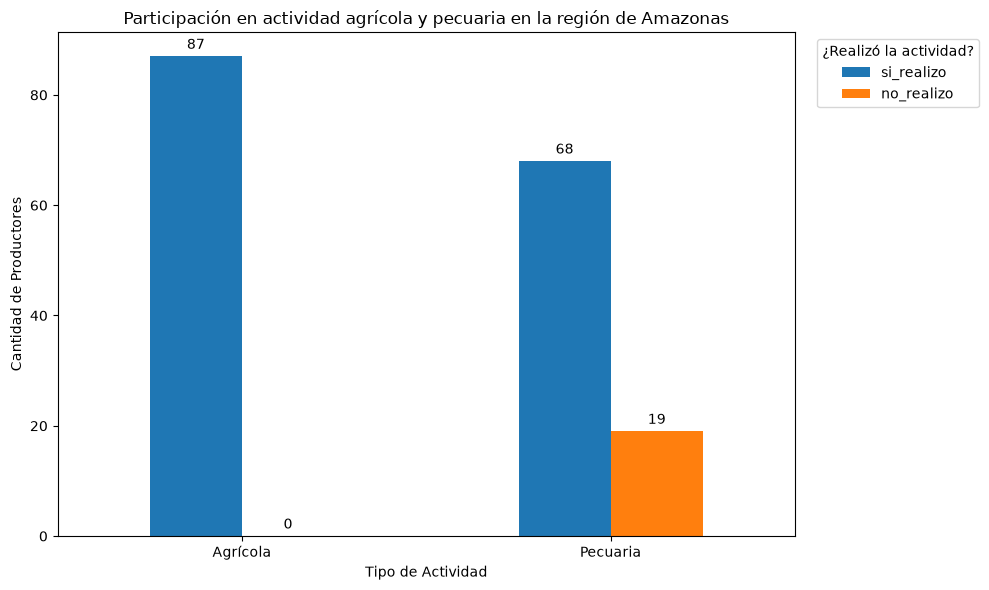

In [205]:
gr_reg_tipo_ama = tabla_p142_ama.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
)

gr_reg_tipo_ama.set_title("Participación en actividad agrícola y pecuaria en la región de Amazonas")
gr_reg_tipo_ama.set_xlabel("Tipo de Actividad")
gr_reg_tipo_ama.set_ylabel("Cantidad de Productores")  

gr_reg_tipo_ama.legend(
    title="¿Realizó la actividad?",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_reg_tipo_ama.containers:
    gr_reg_tipo_ama.bar_label(
        container,
        fmt="%d",
        label_type="edge",  
        padding=3,         
        fontsize=10
    )

plt.xticks(ticks=[0, 1], labels=["Agrícola", "Pecuaria"], rotation=0)

plt.tight_layout()
plt.show()

### 2-. Cultivos que sufrieron pérdida total de producción o superficie(P224B)

In [146]:
df_ama_p224b = df_amazonas.dropna(subset=["P224B_NOM"])

}tabla_p224b_ama = df_ama_p224b["P224B_NOM"].value_counts().reset_index()
tabla_p224b_ama.columns = ["cultivo_afectado", "cantidad_casos"]

total_casos = tabla_p224b_ama["cantidad_casos"].sum()
tabla_p224b_ama["porcentaje"] = (tabla_p224b_ama["cantidad_casos"] / total_casos) * 100

tabla_p224b_ama = tabla_p224b_ama.sort_values("cantidad_casos", ascending=False).reset_index(drop=True)

display(tabla_p224b_ama)


df_grafico_p224b = tabla_p224b_ama.set_index("cultivo_afectado")[["porcentaje"]]

,cultivo_afectado,cantidad_casos,porcentaje
0,MAIZ AMARILLO DURO,17,19.540230
1,PLATANO,13,14.942529
2,ARROZ CASCARA,10,11.494253
3,FRIJOL PINTO,6,6.896552
4,CAFE PERGAMINO,6,6.896552
5,NARANJO,4,4.597701
6,MAIZ AMILACEO,3,3.448276
7,YUCA,3,3.448276
8,PAPA BLANCA,2,2.298851
9,FRIJOL SHINGO,2,2.298851


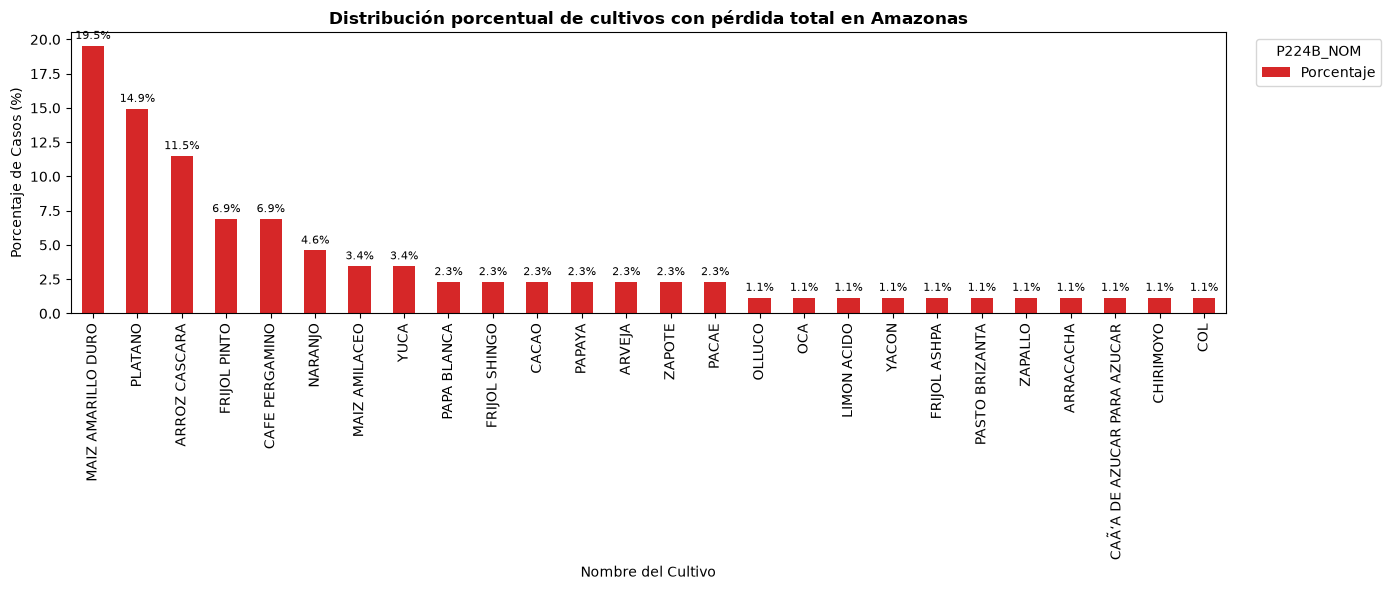

In [144]:
gr_p224b_ama = df_grafico_p224b.plot(
    kind="bar",
    stacked=False,
    figsize=(14, 6),
    color="#d62728"
)

gr_p224b_ama.set_title("Distribución porcentual de cultivos con pérdida total en Amazonas", fontsize=12, fontweight="bold")
gr_p224b_ama.set_xlabel("Nombre del Cultivo", fontsize=10)
gr_p224b_ama.set_ylabel("Porcentaje de Casos (%)", fontsize=10)  

gr_p224b_ama.legend(
    ["Porcentaje"],
    title="P224B_NOM",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_p224b_ama.containers:
    gr_p224b_ama.bar_label(
        container,
        fmt="%.1f%%",  
        label_type="edge", 
        padding=3,         
        fontsize=8        
    )

plt.xticks(rotation=90, ha="center")
plt.tight_layout()
plt.show()

### 3-. ¿CUÁL FUE LA SUPERFICIE SEMBRADA/INSTALADA DE ?(P224D_SUP_1)(P224D_SUP_2)

### -la superficie sembrada o instalada de un cultivo

In [147]:
cols_sup = ["P224D_SUP_1", "P224D_SUP_2"]

df_amazonas[cols_sup] = df_amazonas[cols_sup].apply(pd.to_numeric, errors="coerce")

df_amazonas["SUPERFICIE_TOTAL"] = df_amazonas["P224D_SUP_1"] + (df_amazonas["P224D_SUP_2"]/1000)

tabla_sup_ama = df_amazonas.groupby("NOMBREPV")[["SUPERFICIE_TOTAL"]].sum().reset_index()
tabla_sup_ama.columns = ["provincia", "superficie_total"]

tabla_sup_ama

,provincia,superficie_total
0,BAGUA,39.865
1,BONGARA,5.423
2,CHACHAPOYAS,1.281
3,CONDORCANQUI,16.250
4,LUYA,1.279
5,RODRIGUEZ DE MENDOZA,0.050
6,UTCUBAMBA,60.621


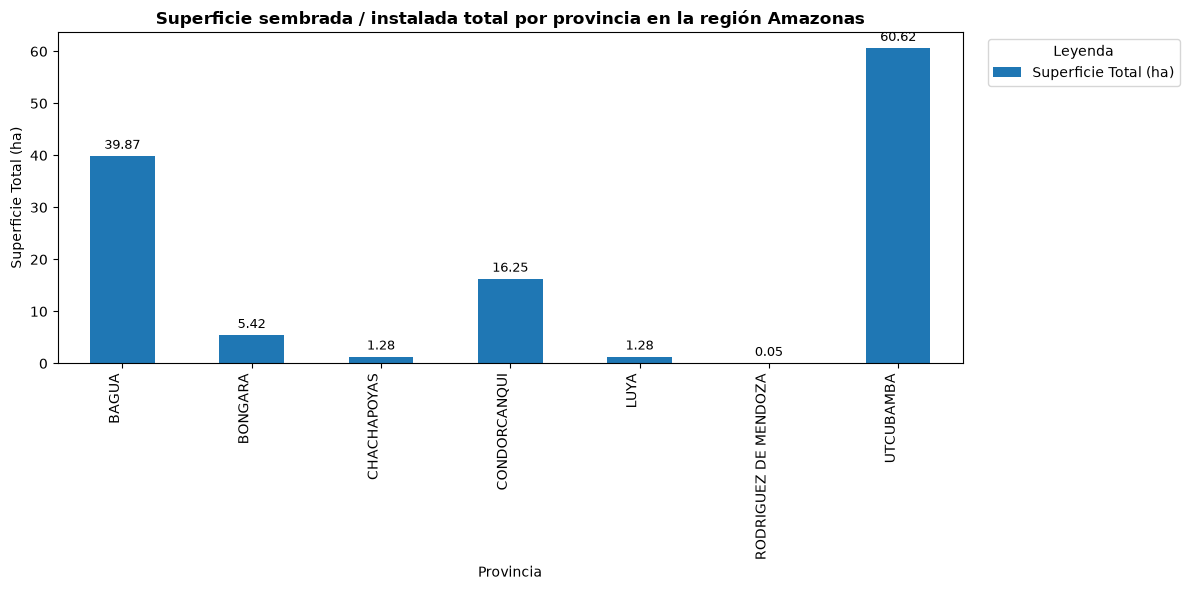

In [154]:
tabla_sup_ama.columns = ["provincia", "Superficie Total (ha)"]

df_grafico_sup = tabla_sup_ama.set_index("provincia")[["Superficie Total (ha)"]]

gr_sup_ama = df_grafico_sup.plot(
    kind="bar",
    stacked=False,
    figsize=(12, 6),
    color="#1f77b4"  
)

gr_sup_ama.set_title("Superficie sembrada / instalada total por provincia en la región Amazonas", fontsize=12, fontweight="bold")
gr_sup_ama.set_xlabel("Provincia", fontsize=10)
gr_sup_ama.set_ylabel("Superficie Total (ha)", fontsize=10)  

gr_sup_ama.legend(
    title="Leyenda",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_sup_ama.containers:
    gr_sup_ama.bar_label(
        container,
        fmt="%.2f",  
        label_type="edge",
        padding=3,     
        fontsize=9
    )

plt.xticks(rotation=90, ha="right")
plt.tight_layout()
plt.show()

### 4-.EN QUE CULTIVOS SEMBRADOS/INSTALADOS TUVO PERDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS?

In [72]:
resumen_tipo_cultivo_ama = pd.crosstab(
    df_amazonas["NOMBREPV"],
    df_amazonas["P224B_TIPO"],
    normalize = "index",
)*100
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.round(2)
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.rename(columns={
    "1": "Transitorio",
    "2": "Permanente_Estacional",
    "3": "Permanente_Continua"
})
resumen_tipo_cultivo_ama

P224B_TIPO,1,2,3
NOMBREPV,,,
BAGUA,45.45,18.18,36.36
BONGARA,83.33,16.67,0.00
CHACHAPOYAS,100.00,0.00,0.00
CONDORCANQUI,0.00,0.00,100.00
LUYA,66.67,33.33,0.00
RODRIGUEZ DE MENDOZA,0.00,100.00,0.00
UTCUBAMBA,62.86,20.00,17.14


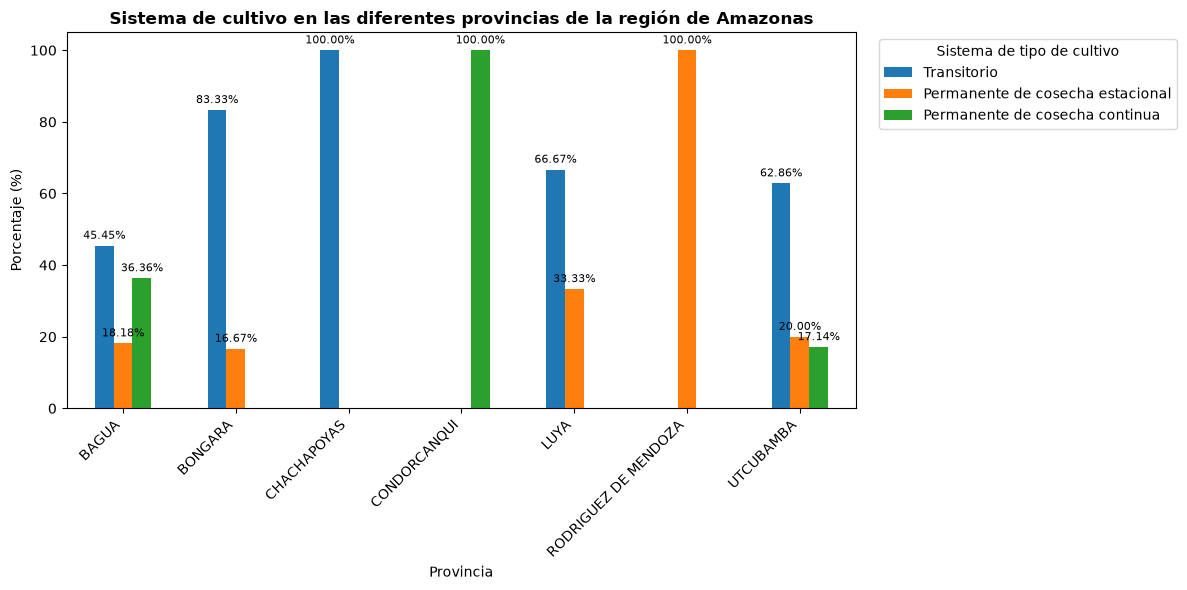

In [156]:
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_ama.rename(columns={
    1: "Transitorio",
    2: "Permanente de cosecha estacional",
    3: "Permanente de cosecha continua"
})

gr_reg_tipo_ama = resumen_tipo_cultivo_ama.plot(
    kind="bar",
    stacked=False,
    figsize=(12, 6)
)

gr_reg_tipo_ama.set_title("Sistema de cultivo en las diferentes provincias de la región de Amazonas", fontsize=12, fontweight="bold")
gr_reg_tipo_ama.set_xlabel("Provincia", fontsize=10)
gr_reg_tipo_ama.set_ylabel("Porcentaje (%)", fontsize=10)  

gr_reg_tipo_ama.legend(
    title="Sistema de tipo de cultivo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_reg_tipo_ama.containers:
    # Filtramos para que no imprima ceros feos
    gr_reg_tipo_ama.bar_label(
        container,
        labels=[f"{v:.2f}%" if v > 0 else "" for v in container.datavalues],
        label_type="edge",  
        padding=3,          
        fontsize=8          
    )

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 5-.¿CUÁL FUE EL MOTIVO DE LA PÉRDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS? (P224E_1)...(PP224E_7)

In [81]:
cols_factores = [f"P224E_{i}" for i in range(1, 8)]

df_amazonas[cols_factores] = df_amazonas[cols_factores].apply(
    pd.to_numeric,
    errors="coerce"
)

factores_ama = df_amazonas[cols_factores]

nombres_factores = [
    "huaycos, deslizamientos o derrumbes",
    "inundaciones",
    "plagas y/o emfermedades",
    "heladas",
    "granizada",
    "sequia",
    "Otros"
]

tabla_ama = pd.DataFrame({
    "factor": nombres_factores,
    "si_afecto": [factores_ama[c].eq(1).sum() for c in cols_factores],
    "no_afecto": [factores_ama[c].eq(0).sum() for c in cols_factores]
})

tabla_ama["porcentaje_falla"] = (
    tabla_ama["si_afecto"] /
    (tabla_ama["si_afecto"] + tabla_ama["no_afecto"]) * 100
).round(2)

tabla_ama

,factor,si_afecto,no_afecto,porcentaje_falla
0,"huaycos, deslizamientos o derrumbes",8,79,9.20
1,inundaciones,14,73,16.09
2,plagas y/o emfermedades,24,63,27.59
3,heladas,2,85,2.30
4,granizada,0,87,0.00
5,sequia,54,33,62.07
6,Otros,5,82,5.75


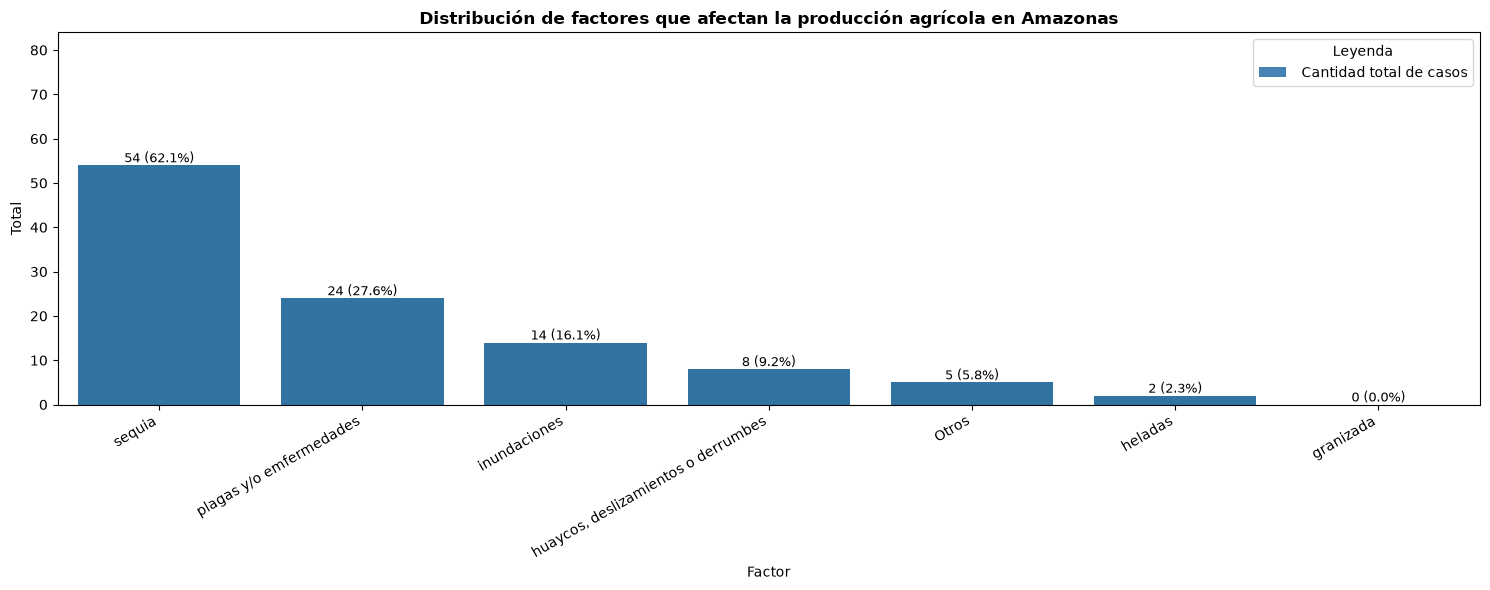

In [161]:
tabla_frecuencias_factores_ama = tabla_ama.sort_values(
    "si_afecto",
    ascending=False
)

plt.figure(figsize=(15, 6))

g_ama_fac = sns.barplot(
    data=tabla_frecuencias_factores_ama, 
    x="factor",
    y="si_afecto" 
)

for i, barra in enumerate(g_ama_fac.patches):    
    conteo = tabla_frecuencias_factores_ama["si_afecto"].iloc[i]
    porcentaje = tabla_frecuencias_factores_ama["porcentaje_falla"].iloc[i]

    g_ama_fac.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(), 
        f"{conteo} ({porcentaje:.1f}%)",
        ha="center", 
        va="bottom",
        fontsize=9
    )

plt.ylim(0, tabla_frecuencias_factores_ama["si_afecto"].max() + 30)

plt.title("Distribución de factores que afectan la producción agrícola en Amazonas", fontsize=12, fontweight="bold")
plt.xlabel("Factor", fontsize=10)
plt.ylabel("Total", fontsize=10)

plt.xticks(rotation=30, ha="right")

slegend_elements = [
    Patch(facecolor='steelblue', label=' Cantidad total de casos')
]
plt.legend(handles=legend_elements, title="Leyenda", loc="upper right")

plt.tight_layout()
plt.show()

### 6-. EN LOS ÚLTIMOS 12 MESES A NIVEL NACIONAL, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Agrícola? (P142_1)

In [189]:
resumen_agricola_peru = df_cap200b.groupby("NOMBREDD").agg(
    total_agricola = ("P142_1", lambda x: (x == 1).sum())
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "total_agricola": [resumen_agricola_peru["total_agricola"].sum()]
})

tabla_agricola_con_total = pd.concat([resumen_agricola_peru, fila_total], ignore_index=True)

display(tabla_agricola_con_total)

,NOMBREDD,total_agricola
0,AMAZONAS,87
1,ANCASH,209
2,APURIMAC,106
3,AREQUIPA,170
4,AYACUCHO,481
5,CAJAMARCA,322
6,CUSCO,409
7,HUANCAVELICA,214
8,HUANUCO,140
9,ICA,64


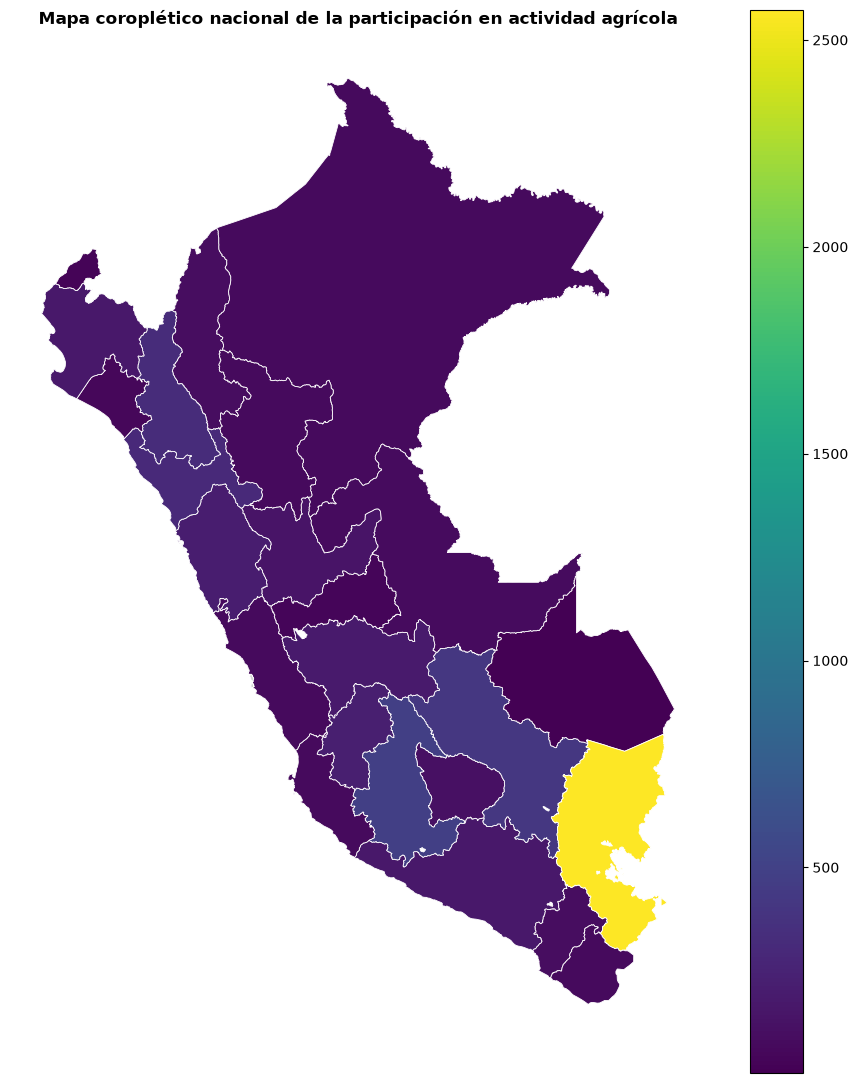

In [190]:
peru_agricola_merge = peru.merge(
    resumen_agricola_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
)

fig, ax = plt.subplots(figsize=(9, 11))

peru_agricola_merge.plot(
    column="total_agricola",  
    cmap="viridis",             
    legend=True,               
    edgecolor="white",          
    linewidth=0.6,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title("Mapa coroplético nacional de la participación en actividad agrícola", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

### 7-. EN LOS ÚLTIMOS 12 MESES A NIVEL NACIONAL, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Pecuaria? (P142_2)

In [201]:
resumen_pecuaria_peru = df_cap200b.groupby("NOMBREDD").agg(
    total_pecuaria = ("P142_2", lambda x: (x == 1).sum())
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "total_pecuaria": [resumen_pecuaria_peru["total_pecuaria"].sum()]
})

tabla_pecuaria_con_total = pd.concat([resumen_pecuaria_peru, fila_total], ignore_index=True)

display(tabla_pecuaria_con_total)

,NOMBREDD,total_pecuaria
0,AMAZONAS,68
1,ANCASH,186
2,APURIMAC,100
3,AREQUIPA,120
4,AYACUCHO,411
5,CAJAMARCA,303
6,CUSCO,381
7,HUANCAVELICA,199
8,HUANUCO,127
9,ICA,34


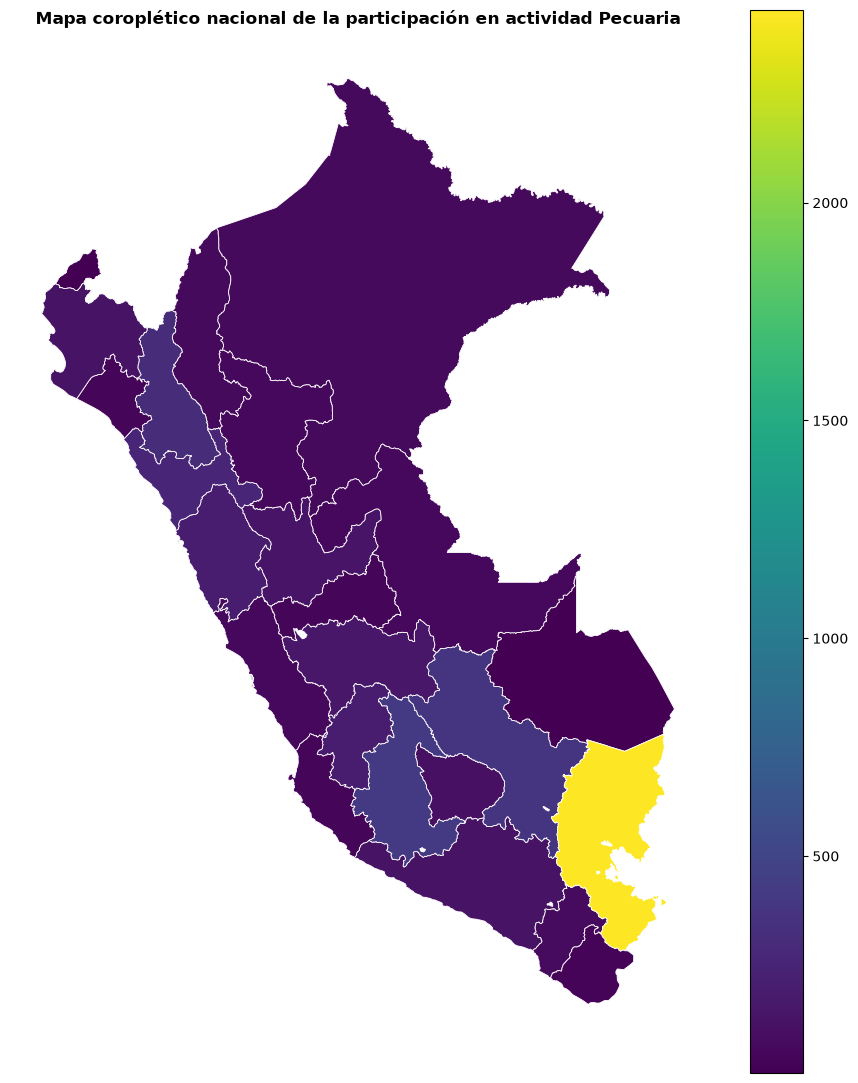

In [204]:
peru_pecuaria_merge = peru.merge(
    resumen_pecuaria_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
)

fig, ax = plt.subplots(figsize=(9, 11))

peru_pecuaria_merge.plot(
    column="total_pecuaria",  
    cmap="viridis",             
    legend=True,               
    edgecolor="white",          
    linewidth=0.6,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title("Mapa coroplético nacional de la participación en actividad Pecuaria", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

### 8-. Superficie Agrícola Total  sembrada/instalada a Nivel Nacional (P224D_SUP_1)-(P224D_SUP_2)

In [197]:
df_cap200b["superficie_total"] = df_cap200b["P224D_SUP_1"] + (df_cap200b["P224D_SUP_2"] / 1000)

resumen_sup_peru = df_cap200b.groupby("NOMBREDD").agg(
    superficie_total = ("superficie_total", "sum")
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "superficie_total": [resumen_sup_peru["superficie_total"].sum()]
})

tabla_sup_con_total = pd.concat([resumen_sup_peru, fila_total], ignore_index=True)

display(tabla_sup_con_total)

,NOMBREDD,superficie_total
0,AMAZONAS,124.77
1,ANCASH,37490.68
2,APURIMAC,6477.49
3,AREQUIPA,770.43
4,AYACUCHO,6945.44
5,CAJAMARCA,92.05
6,CUSCO,297384.53
7,HUANCAVELICA,20849.25
8,HUANUCO,50.91
9,ICA,53.69


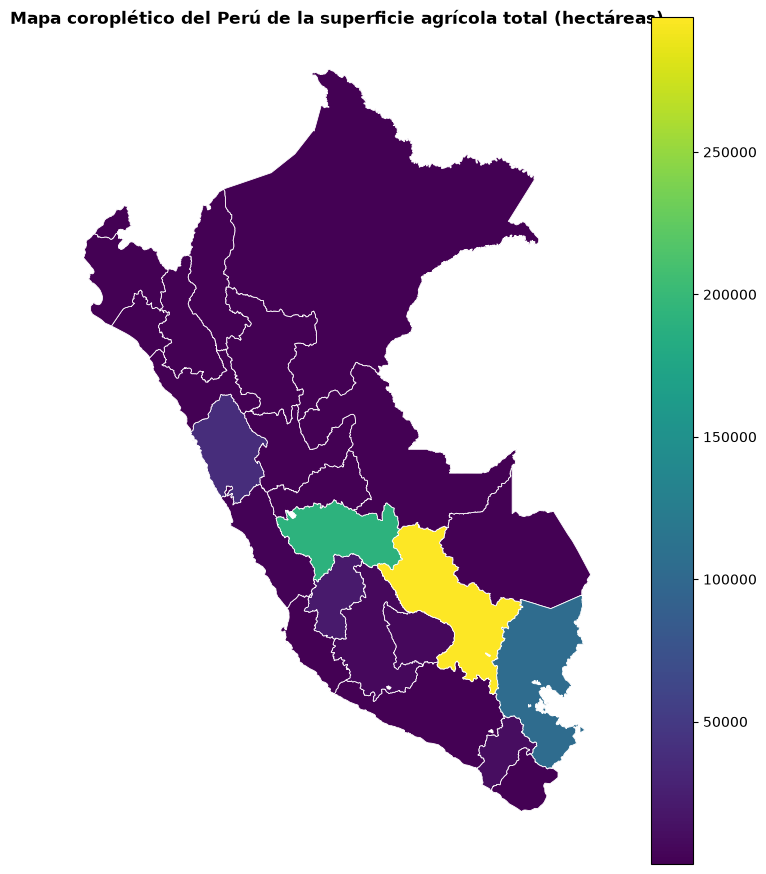

In [198]:
peru_sup_merge = peru.merge(
    resumen_sup_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
).copy()

fig, ax = plt.subplots(figsize=(9, 11))

peru_sup_merge.plot(
    column="superficie_total",
    cmap="viridis",             
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

ax.set_title("Mapa coroplético del Perú de la superficie agrícola total (hectáreas)", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.show()

# Segundo Avance Laboratorio 2

In [6]:
df_cap200b["CULTIVO"] = df_cap200b["P224B_NOM"].str.upper()

In [19]:
df_frijol = df_cap200b[df_cap200b["CULTIVO"].str.contains("FRIJOL|FRÍJOL", case=False, na=False)].copy()
df_frijol["CULTIVO"] = "FRIJOL"

display(df_frijol["CULTIVO"].value_counts())

CULTIVO
FRIJOL    91
Name: count, dtype: int64

In [20]:
df_maiz = df_cap200b[df_cap200b["CULTIVO"].str.contains("MAIZ|MAÍZ", case=False, na=False)].copy()
df_maiz["CULTIVO"] = "MAIZ"

display(df_maiz["CULTIVO"].value_counts())

CULTIVO
MAIZ    654
Name: count, dtype: int64

In [21]:
df_haba = df_cap200b[df_cap200b["CULTIVO"].str.contains("HABA", case=False, na=False)].copy()
df_haba["CULTIVO"] = "HABA"

display(df_haba["CULTIVO"].value_counts())

CULTIVO
HABA    362
Name: count, dtype: int64

## 1: Cantidad de registros agrícolas por provincia (NOMBREP, ID_PROD)
### - Provincias de Áncash presentan mayor cantidad de registros agrícolas.

In [92]:
def limpiar_texto_serie(serie):
    return (
        serie.astype(str)
        .str.upper()
        .str.strip()
        .str.replace("Á", "A", regex=False)
        .str.replace("É", "E", regex=False)
        .str.replace("Í", "I", regex=False)
        .str.replace("Ó", "O", regex=False)
        .str.replace("Ú", "U", regex=False)
        .str.replace("Ü", "U", regex=False)
    )

cultivos_interes = [
    "ARROZ CASCARA", "PALTO", "PAPA AMARGA", "PAPA AMARILLA", 
    "PAPA BLANCA", "PAPA COLOR", "PAPA HUAYRO", "PAPA NATIVA", 
    "CAMOTE", "MANGO", "MANDARINA", "CACAO", "TRIGO", "CAFE", 
    "LIMON", "NARANJO", "YUCA", "PLATANO", "MANZANO"
]

df_filtrado = df_cap200b[limpiar_texto_serie(df_cap200b["CULTIVO"]).isin(cultivos_interes)]

tabla1 = (
    df_filtrado.groupby("CULTIVO")
    .agg(Total=("CULTIVO", "count"))
    .sort_values(by="Total", ascending=False)
)

display(tabla1)

,Total
CULTIVO,
PAPA NATIVA,718
PAPA BLANCA,375
PLATANO,98
TRIGO,88
ARROZ CASCARA,80
PALTO,71
PAPA AMARILLA,63
PAPA AMARGA,59
CACAO,57


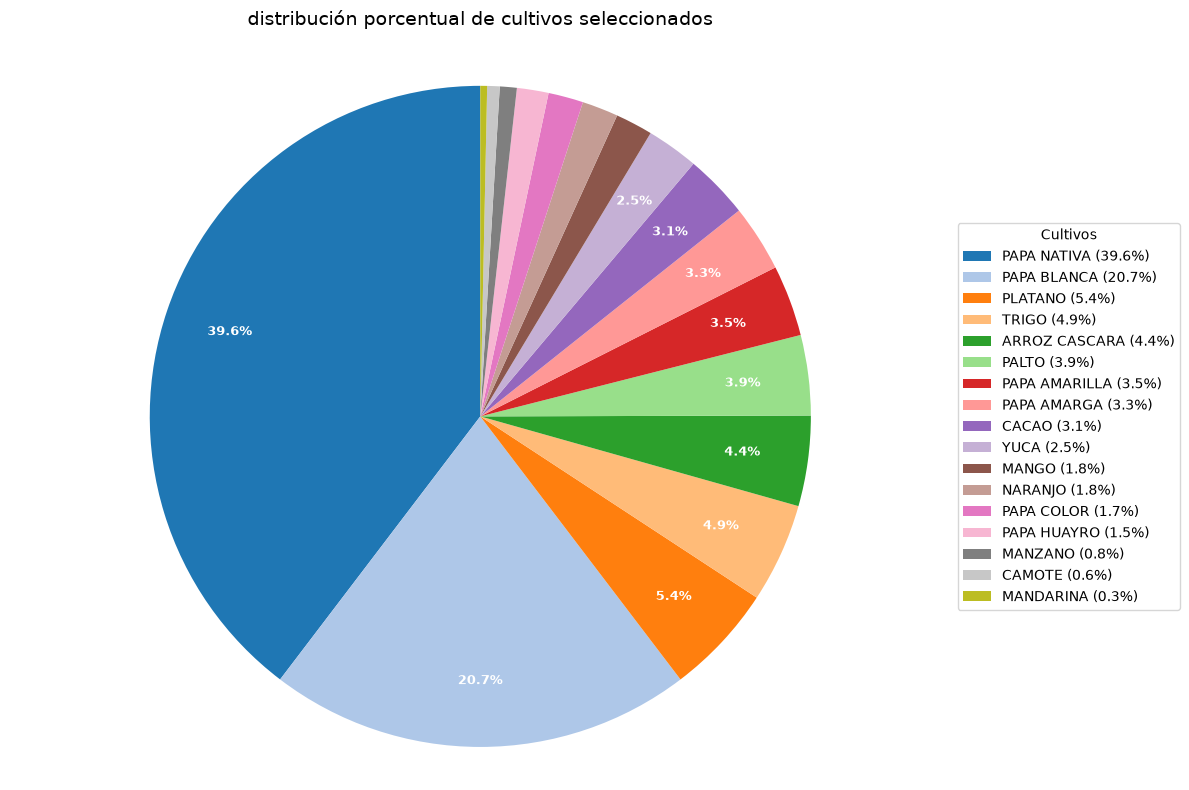

In [93]:
fig, ax = plt.subplots(figsize=(12, 8))

def mostrar_porcentaje(pct):
    return f'{pct:.1f}%' if pct >= 2 else ''

wedges, texts, autotexts = ax.pie(
    tabla1["Total"],
    autopct=mostrar_porcentaje,
    startangle=90,
    pctdistance=0.8,
    colors=plt.cm.tab20.colors # Paleta de 20 colores distintos para que no se repitan
)

plt.setp(autotexts, size=9, weight="bold", color="white")

porcentajes = (tabla1["Total"] / tabla1["Total"].sum()) * 100
etiquetas_leyenda = [f"{cultivo} ({pct:.1f}%)" for cultivo, pct in zip(tabla1.index, porcentajes)]

ax.legend(
    wedges,
    etiquetas_leyenda,
    title="Cultivos",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("distribución porcentual de cultivos seleccionados", fontsize=14, pad=20)
ax.axis("equal") 
plt.tight_layout()
plt.show()

2

# 3 ANCASH:

In [31]:
cols_a_borrar = [c for c in df.columns if "NOMBREDD" in c]
df = df.drop(columns=cols_a_borrar)

In [32]:
ubigeos = datos[["CCDD", "NOMBREDD"]].drop_duplicates()
df = df.merge(ubigeos, on="CCDD", how="left")

In [33]:
df_ancash = df[df["NOMBREDD"] == "ANCASH"].copy()

In [34]:
claves = [
    "ANIO", "CCDD", "CCPP", "CCDI",
    "NSEGM", "ID_PROD", "UA"
]

df = pd.merge(
    df_CARATULA,
    df_cap200b,
    on=claves,
    how="inner"
)

display(df.head())

,ANIO,CCDD,NOMBREDD_x,CCPP,NOMBREPV_x,CCDI,NOMBREDI_x,NSEGM,ID_PROD,UA,...,P224D_SUP_2,P224E_1,P224E_2,P224E_3,P224E_4,P224E_5,P224E_6,P224E_7,OMICAP200_00,CULTIVO
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,6.0,CHUQUIBAMBA,30016,6,6,...,50,0,0,1,0,0,0,0,,FRIJOL
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,9.0,LA JALCA,30023,3,3,...,500,0,0,0,0,0,1,0,,PAPA BLANCA
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,9.0,LA JALCA,30023,3,3,...,301,0,0,0,0,0,1,0,,PAPA BLANCA
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,17.0,QUINJALCA,30046,1,1,...,400,0,0,1,1,0,1,0,,OLLUCO
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,17.0,QUINJALCA,30046,1,1,...,30,0,0,1,1,0,1,0,,OCA


## 2-. Cultivos más frecuentes en Áncash (NOMBREPV)(ID_PROD)
### -registros agrícolas por provincia de Áncash

In [40]:
tabla1 = df_ancash.groupby("NOMBREPV").agg(
    Total_registros=("ID_PROD", "count"),
    Productores=("ID_PROD", "nunique")
).sort_values(
    by="Total_registros",
    ascending=False
)

display(tabla1)

,Total_registros,Productores
NOMBREPV,,
SANTA,49,9
HUARAZ,37,7
PALLASCA,32,8
AIJA,20,6
HUARI,13,4
CARHUAZ,8,5
ANTONIO RAYMONDI,7,4
BOLOGNESI,7,5
RECUAY,6,3


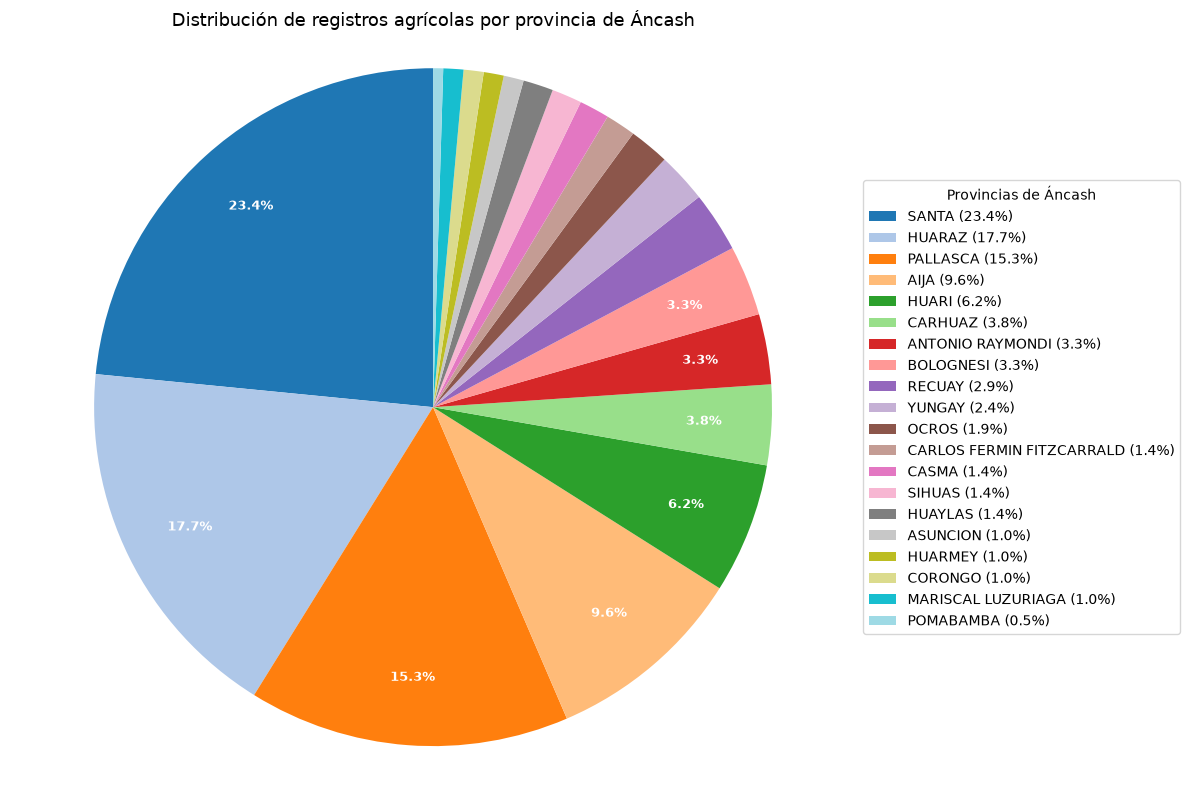

In [42]:
fig, ax = plt.subplots(figsize=(12, 8))

def mostrar_pct(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

wedges, texts, autotexts = ax.pie(
    tabla1["Total_registros"],
    autopct=mostrar_pct,
    startangle=90,
    pctdistance=0.8,
    colors=plt.cm.tab20.colors
)

plt.setp(autotexts, size=9, weight="bold", color="white")

porcentajes = (tabla1["Total_registros"] / tabla1["Total_registros"].sum()) * 100
etiquetas = [f"{prov} ({pct:.1f}%)" for prov, pct in zip(tabla1.index, porcentajes)]

ax.legend(
    wedges,
    etiquetas,
    title="Provincias de Áncash",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Distribución de registros agrícolas por provincia de Áncash", fontsize=13)
ax.axis("equal")
plt.tight_layout()
plt.show()

## 3-.Cultivos más frecuentes en Áncash(CULTIVO)
### -identificar los cultivos con mayor presencia en Áncash.

In [43]:
tabla3 = df_ancash.groupby("CULTIVO").agg(
    Total_registros=("CULTIVO", "count")
).sort_values(
    by="Total_registros",
    ascending=False
)

display(tabla3)

,Total_registros
CULTIVO,
PAPA BLANCA,55
PALTO,30
MAIZ,25
ARVEJA,13
TARHUI,11
TRIGO,10
HABA,8
OCA,4
PAPA NATIVA,4


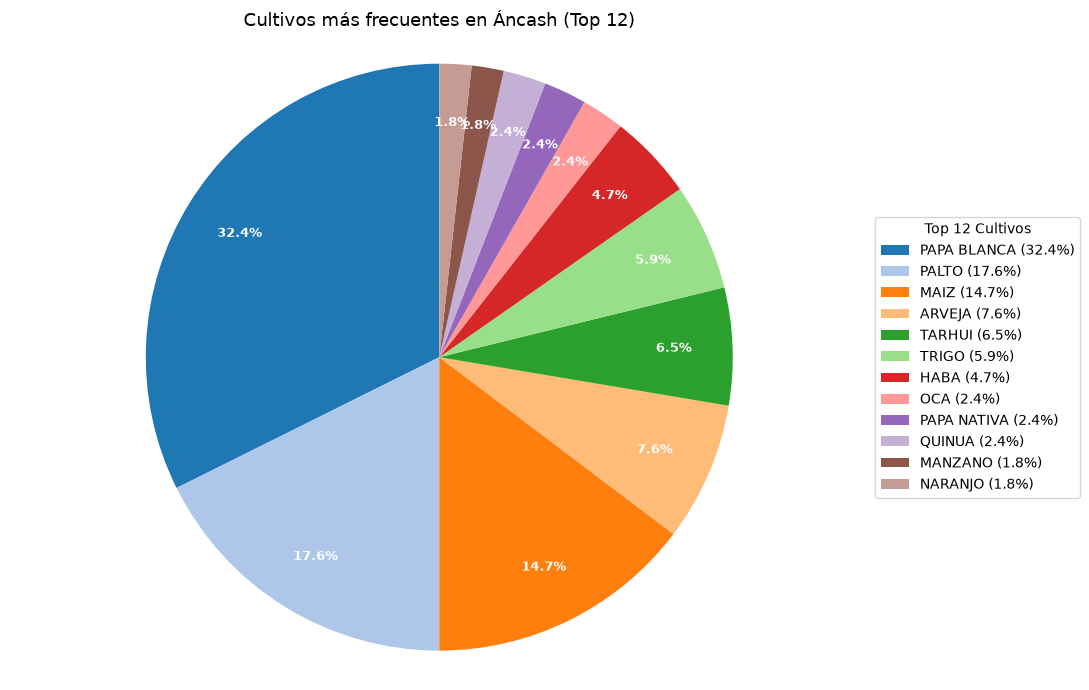

In [44]:
top12 = tabla3.head(12)

fig, ax = plt.subplots(figsize=(11, 7))

wedges, texts, autotexts = ax.pie(
    top12["Total_registros"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8,
    colors=plt.cm.tab20.colors
)

plt.setp(autotexts, size=9, weight="bold", color="white")

# Leyenda lateral con el nombre del cultivo y su porcentaje
porcentajes = (top12["Total_registros"] / top12["Total_registros"].sum()) * 100
etiquetas = [f"{cultivo} ({pct:.1f}%)" for cultivo, pct in zip(top12.index, porcentajes)]

ax.legend(
    wedges,
    etiquetas,
    title="Top 12 Cultivos",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Cultivos más frecuentes en Áncash (Top 12)", fontsize=13)
ax.axis("equal")
plt.tight_layout()
plt.show()

## 4-. Cantidad de registros por provincia utilizando transform() -(NOMBREP), (ID_PROD), (TOTAL_PROVINCIA)
### -total de registros agrícolas por provincia utilizando transform().

In [45]:
df_ancash["TOTAL_PROVINCIA"] = df_ancash.groupby(
    "NOMBREPV"
)["ID_PROD"].transform("count")

tabla4 = df_ancash.groupby("NOMBREPV").agg(
    Total_registros=("TOTAL_PROVINCIA", "mean")
).sort_values(
    by="Total_registros",
    ascending=False
)

display(tabla4)

,Total_registros
NOMBREPV,
SANTA,49.0
HUARAZ,37.0
PALLASCA,32.0
AIJA,20.0
HUARI,13.0
CARHUAZ,8.0
ANTONIO RAYMONDI,7.0
BOLOGNESI,7.0
RECUAY,6.0


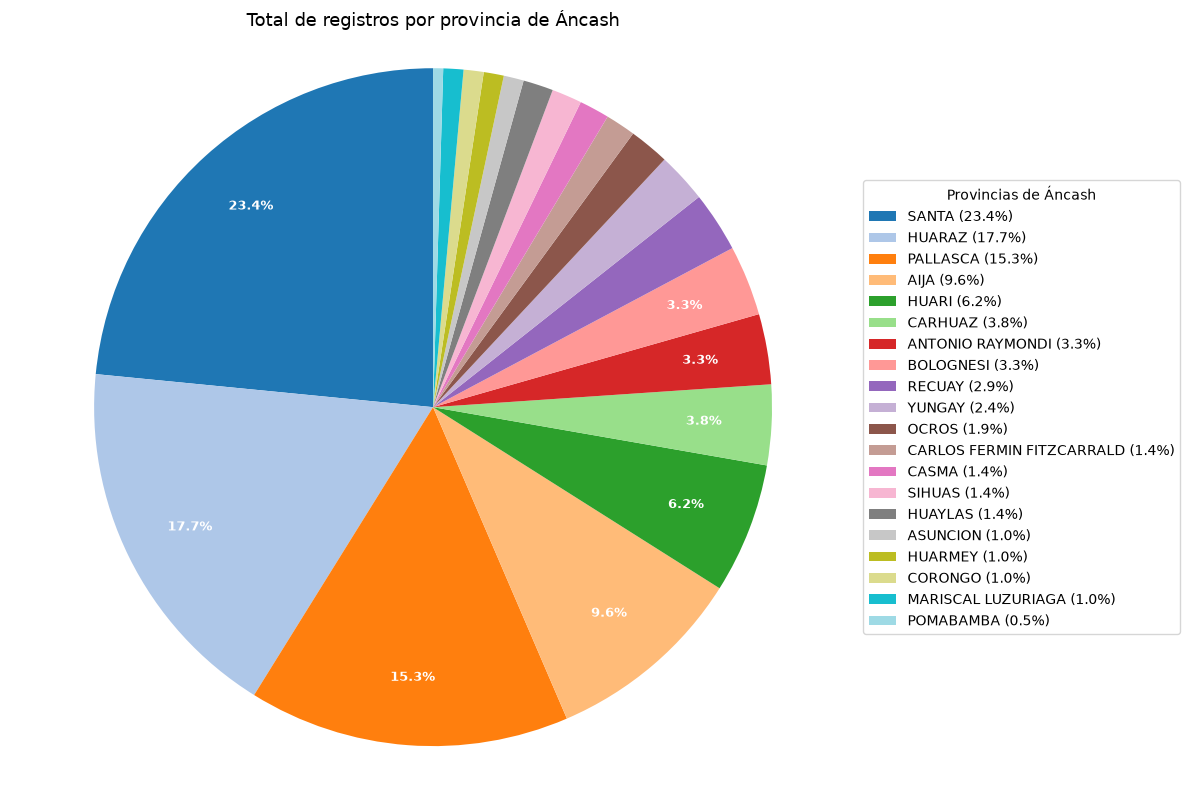

In [46]:
fig, ax = plt.subplots(figsize=(12, 8))

def mostrar_pct(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

wedges, texts, autotexts = ax.pie(
    tabla4["Total_registros"],
    autopct=mostrar_pct,
    startangle=90,
    pctdistance=0.8,
    colors=plt.cm.tab20.colors
)

plt.setp(autotexts, size=9, weight="bold", color="white")

porcentajes = (tabla4["Total_registros"] / tabla4["Total_registros"].sum()) * 100
etiquetas = [f"{prov} ({pct:.1f}%)" for prov, pct in zip(tabla4.index, porcentajes)]

ax.legend(
    wedges,
    etiquetas,
    title="Provincias de Áncash",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Total de registros por provincia de Áncash", fontsize=13)
ax.axis("equal")
plt.tight_layout()
plt.show()

## 5-. Principales cultivos por provincia de Áncash (NOMBREP), (CULTIVO)
### - Los cultivos  que predominan en cada provincia.

In [47]:
tabla5 = df_ancash.groupby(
    ["NOMBREPV", "CULTIVO"]
).agg(
    Total_registros=("CULTIVO", "count")
).sort_values(
    by="Total_registros",
    ascending=False
)

display(tabla5)

Total_registros
NOMBREPV CULTIVO                     
SANTA    PALTO                     26
HUARAZ   PAPA BLANCA               16
AIJA     PAPA BLANCA               10
PALLASCA PAPA BLANCA                8
         MAIZ                       7
...                               ...
SANTA    PAPRIKA                    1
SIHUAS   TARHUI                     1
YUNGAY   ARVEJA                     1
         MAIZ                       1
         QUINUA                     1

[97 rows x 1 columns]

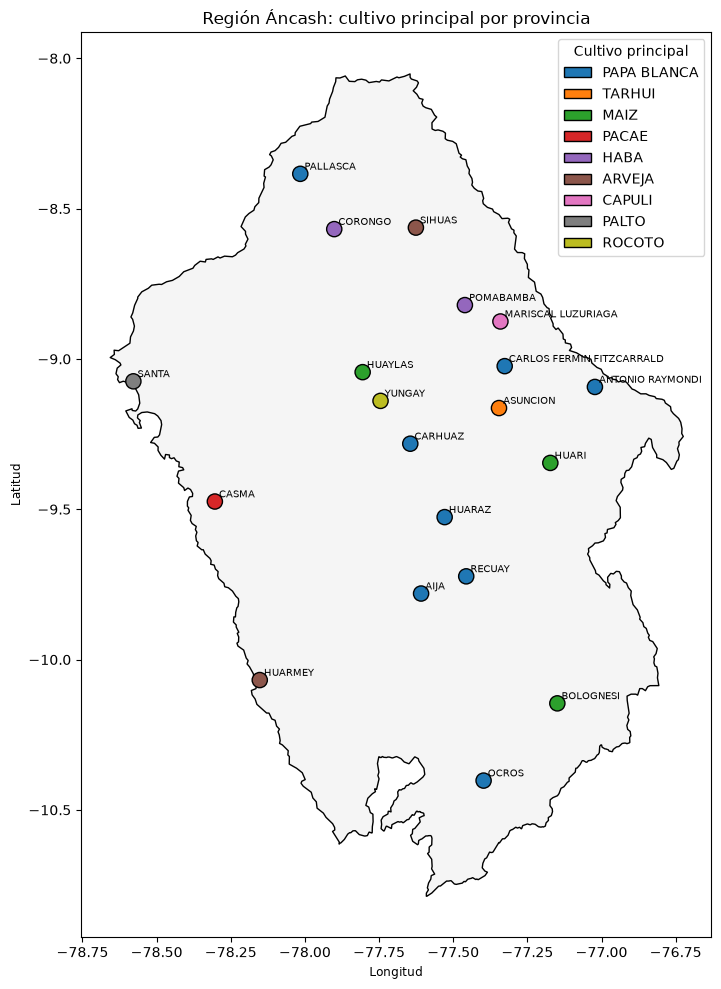

In [51]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ancash = peru[peru["NOMBDEP"].str.upper() == "ANCASH"].copy()

cultivo_principal = (
    tabla5.reset_index()
    .drop_duplicates(subset=["NOMBREPV"])
    .copy()
)
cultivo_principal["NOMBREPV"] = cultivo_principal["NOMBREPV"].str.upper().str.strip()

coords_ancash = pd.DataFrame([
    ("HUARAZ", -77.5288, -9.5261),
    ("AIJA", -77.6083, -9.7803),
    ("ANTONIO RAYMONDI", -77.0222, -9.0931),
    ("ASUNCION", -77.3456, -9.1633),
    ("BOLOGNESI", -77.1489, -10.1456),
    ("CARHUAZ", -77.6447, -9.2819),
    ("CARLOS FERMIN FITZCARRALD", -77.3264, -9.0239),
    ("CASMA", -78.3036, -9.4742),
    ("CORONGO", -77.9011, -8.5681),
    ("HUARI", -77.1725, -9.3458),
    ("HUARMEY", -78.1522, -10.0681),
    ("HUAYLAS", -77.8053, -9.0439),
    ("MARISCAL LUZURIAGA", -77.3408, -8.8753),
    ("OCROS", -77.3975, -10.4025),
    ("PALLASCA", -78.0156, -8.3842),
    ("POMABAMBA", -77.4606, -8.8208),
    ("RECUAY", -77.4561, -9.7231),
    ("SANTA", -78.5783, -9.0744),
    ("SIHUAS", -77.6258, -8.5631),
    ("YUNGAY", -77.7450, -9.1394)
], columns=["NOMBREPV", "LON", "LAT"])

df_puntos = coords_ancash.merge(cultivo_principal, on="NOMBREPV", how="inner")

puntos_ancash = gpd.GeoDataFrame(
    df_puntos,
    geometry=gpd.points_from_xy(df_puntos["LON"], df_puntos["LAT"]),
    crs=ancash.crs
)

cultivos_unicos = puntos_ancash["CULTIVO"].unique()
colores = plt.cm.tab10.colors
mapa_colores = {cultivo: colores[i % len(colores)] for i, cultivo in enumerate(cultivos_unicos)}

puntos_ancash["color_cultivo"] = puntos_ancash["CULTIVO"].map(mapa_colores)

fig, ax = plt.subplots(figsize=(10, 10))

ancash.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black"
)

puntos_ancash.plot(
    ax=ax,
    color=puntos_ancash["color_cultivo"],
    markersize=120,
    edgecolor="black",
    legend=False
)

for _, row in puntos_ancash.iterrows():
    ax.annotate(
        row["NOMBREPV"],
        xy=(row["LON"], row["LAT"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7
    )

elementos_leyenda = [
    Patch(facecolor=color, edgecolor="black", label=cultivo)
    for cultivo, color in mapa_colores.items()
]
ax.legend(
    handles=elementos_leyenda,
    title="Cultivo principal",
    loc="upper right",
    frameon=True
)

ax.set_title("Región Áncash: cultivo principal por provincia")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.tight_layout()
plt.show()

## 6-. ¿CUÁL FUE LA SUPERFICIE SEMBRADA/INSTALADA DE ?(P224D_SUP_1)(P224D_SUP_2)
### -La superficie sembrada o instalada de un cultivo

In [54]:
cols_sup = ["P224D_SUP_1", "P224D_SUP_2"]

df_ancash[cols_sup] = df_ancash[cols_sup].apply(pd.to_numeric, errors="coerce")

df_ancash["SUPERFICIE_TOTAL"] = df_ancash["P224D_SUP_1"] + (df_ancash["P224D_SUP_2"] / 1000)

tabla_sup_anc = (
    df_ancash.groupby("NOMBREPV")[["SUPERFICIE_TOTAL"]]
    .sum()
    .reset_index()
    .sort_values(by="SUPERFICIE_TOTAL", ascending=False)
)
tabla_sup_anc.columns = ["provincia", "superficie_total"]

display(tabla_sup_anc)

,provincia,superficie_total
8,HUARAZ,16304.518
9,HUARI,9900.663
0,AIJA,8202.925
4,CARHUAZ,1800.943
1,ANTONIO RAYMONDI,1250.596
17,SANTA,18.245
14,PALLASCA,5.300
6,CASMA,2.096
19,YUNGAY,1.050
16,RECUAY,0.980


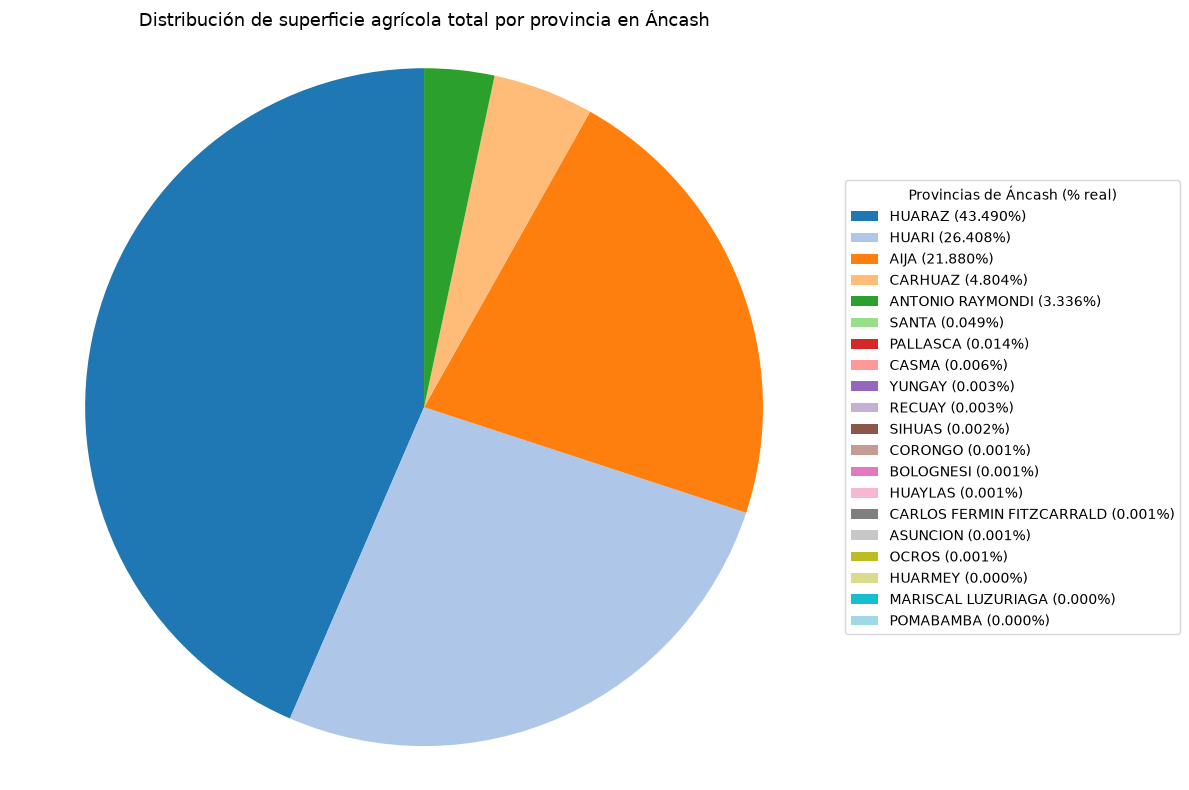

In [59]:

total_ancash = tabla_sup_anc["superficie_total"].sum()
tabla_sup_anc["pct_real"] = (tabla_sup_anc["superficie_total"] / total_ancash) * 100

colores_lista = plt.cm.tab20.colors
tabla_sup_anc["color"] = [colores_lista[i % len(colores_lista)] for i in range(len(tabla_sup_anc))]

provincias_grafico = ["HUARAZ", "HUARI", "AIJA", "CARHUAZ", "ANTONIO RAYMONDI"]
df_pie = tabla_sup_anc[tabla_sup_anc["provincia"].str.upper().isin(provincias_grafico)].copy()

fig, ax = plt.subplots(figsize=(12, 8))

ax.pie(
    df_pie["superficie_total"],
    startangle=90,
    colors=df_pie["color"]
)

handles_leyenda = [
    Patch(
        facecolor=row["color"],
        label=f"{row['provincia']} ({row['pct_real']:.3f}%)"
    )
    for _, row in tabla_sup_anc.iterrows()
]

ax.legend(
    handles=handles_leyenda,
    title="Provincias de Áncash (% real)",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Distribución de superficie agrícola total por provincia en Áncash", fontsize=13)
ax.axis("equal")
plt.tight_layout()
plt.show()

## 7-.EN QUE CULTIVOS SEMBRADOS/INSTALADOS TUVO PERDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS? 

In [62]:
col_tipo = [c for c in df_ancash.columns if "TIPO" in c.upper() or "P224A" in c.upper()][0]
df_ancash[col_tipo] = pd.to_numeric(df_ancash[col_tipo], errors="coerce")

resumen_tipo_cultivo_anc = pd.crosstab(
    df_ancash["NOMBREPV"],
    df_ancash[col_tipo],
    normalize="index"
) * 100

resumen_tipo_cultivo_anc = resumen_tipo_cultivo_anc.rename(columns={
    1: "Transitorio",
    2: "Permanente de cosecha estacional",
    3: "Permanente de cosecha continua"
})

display(resumen_tipo_cultivo_anc)

P224B_TIPO,Transitorio,Permanente de cosecha estacional,Permanente de cosecha continua
NOMBREPV,,,
AIJA,100.000000,0.000000,0.000000
ANTONIO RAYMONDI,100.000000,0.000000,0.000000
ASUNCION,100.000000,0.000000,0.000000
BOLOGNESI,71.428571,28.571429,0.000000
CARHUAZ,100.000000,0.000000,0.000000
CARLOS FERMIN FITZCARRALD,100.000000,0.000000,0.000000
CASMA,33.333333,66.666667,0.000000
CORONGO,100.000000,0.000000,0.000000
HUARAZ,97.297297,0.000000,2.702703


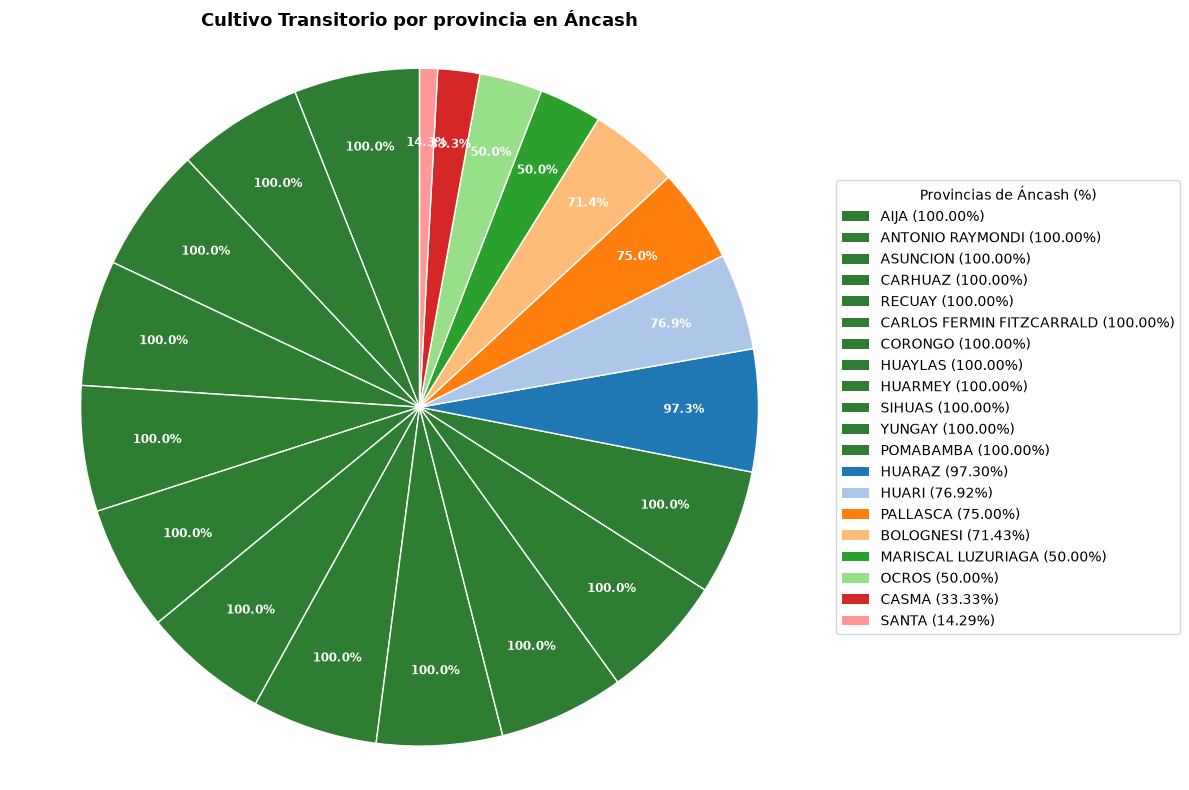

In [69]:
from matplotlib.patches import Patch

col_nombre = "Transitorio"
datos = resumen_tipo_cultivo_anc[col_nombre].sort_values(ascending=False)

color_100 = "#2e7d32"
paleta_otros = [c for c in plt.cm.tab20.colors if c != color_100]

colores_prov = []
idx_otro = 0
for val in datos.values:
    if round(val, 2) == 100:
        colores_prov.append(color_100)
    else:
        colores_prov.append(paleta_otros[idx_otro % len(paleta_otros)])
        idx_otro += 1

datos_pie = datos[datos > 0]
colores_pie = [c for val, c in zip(datos, colores_prov) if val > 0]

iter_valores = iter(datos_pie.values)
def mostrar_valor_real(_):
    val = next(iter_valores)
    return f"{val:.1f}%"

fig, ax = plt.subplots(figsize=(12, 8))

wedges, texts, autotexts = ax.pie(
    datos_pie,
    autopct=mostrar_valor_real,
    pctdistance=0.78,
    startangle=90,
    colors=colores_pie,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.setp(autotexts, size=8.5, weight="bold", color="white")

handles_leyenda = [
    Patch(facecolor=c, label=f"{prov} ({val:.2f}%)")
    for prov, val, c in zip(datos.index, datos.values, colores_prov)
]

ax.legend(
    handles=handles_leyenda,
    title="Provincias de Áncash (%)",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Cultivo {col_nombre} por provincia en Áncash", fontsize=13, fontweight="bold")
ax.axis("equal")
plt.tight_layout()
plt.show()

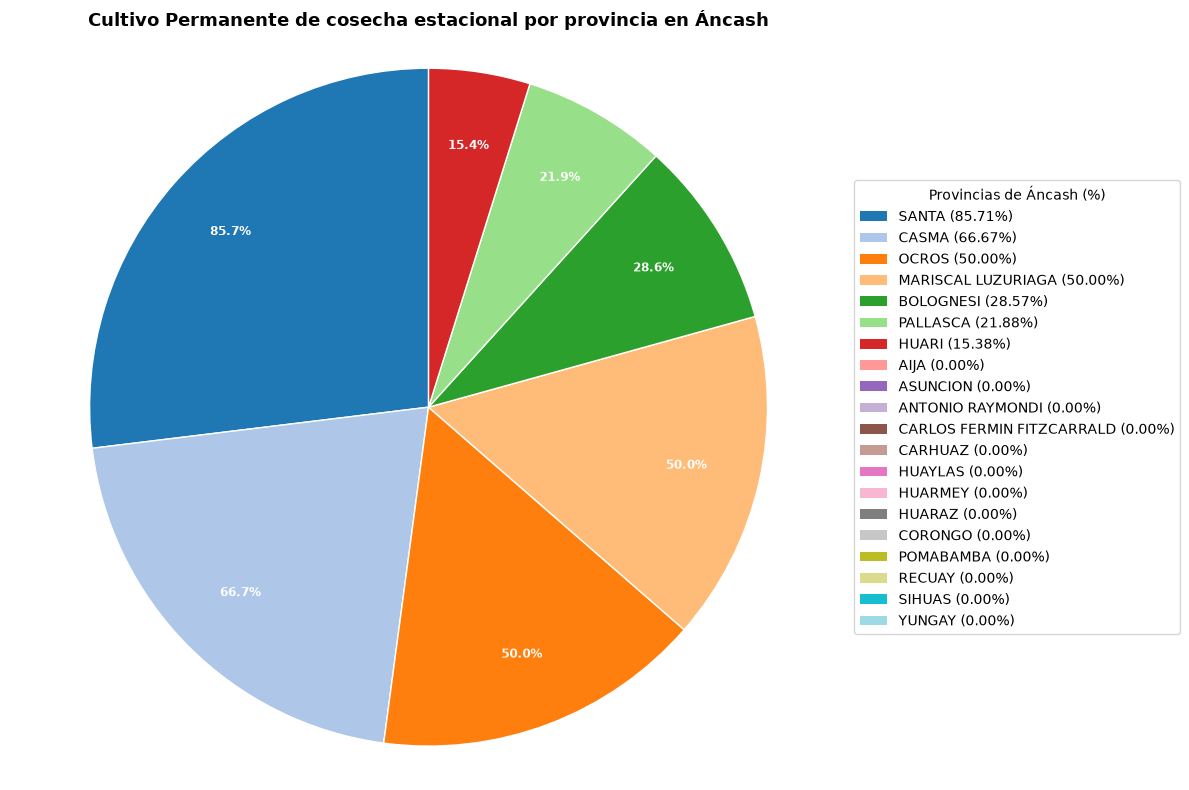

In [70]:
from matplotlib.patches import Patch

col_nombre = "Permanente de cosecha estacional"
datos = resumen_tipo_cultivo_anc[col_nombre].sort_values(ascending=False)

color_100 = "#2e7d32"
paleta_otros = [c for c in plt.cm.tab20.colors if c != color_100]

colores_prov = []
idx_otro = 0
for val in datos.values:
    if round(val, 2) == 100:
        colores_prov.append(color_100)
    else:
        colores_prov.append(paleta_otros[idx_otro % len(paleta_otros)])
        idx_otro += 1

datos_pie = datos[datos > 0]
colores_pie = [c for val, c in zip(datos, colores_prov) if val > 0]

iter_valores = iter(datos_pie.values)
def mostrar_valor_real(_):
    val = next(iter_valores)
    return f"{val:.1f}%"

fig, ax = plt.subplots(figsize=(12, 8))

wedges, texts, autotexts = ax.pie(
    datos_pie,
    autopct=mostrar_valor_real,
    pctdistance=0.78,
    startangle=90,
    colors=colores_pie,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.setp(autotexts, size=8.5, weight="bold", color="white")

handles_leyenda = [
    Patch(facecolor=c, label=f"{prov} ({val:.2f}%)")
    for prov, val, c in zip(datos.index, datos.values, colores_prov)
]

ax.legend(
    handles=handles_leyenda,
    title="Provincias de Áncash (%)",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Cultivo {col_nombre} por provincia en Áncash", fontsize=13, fontweight="bold")
ax.axis("equal")
plt.tight_layout()
plt.show()

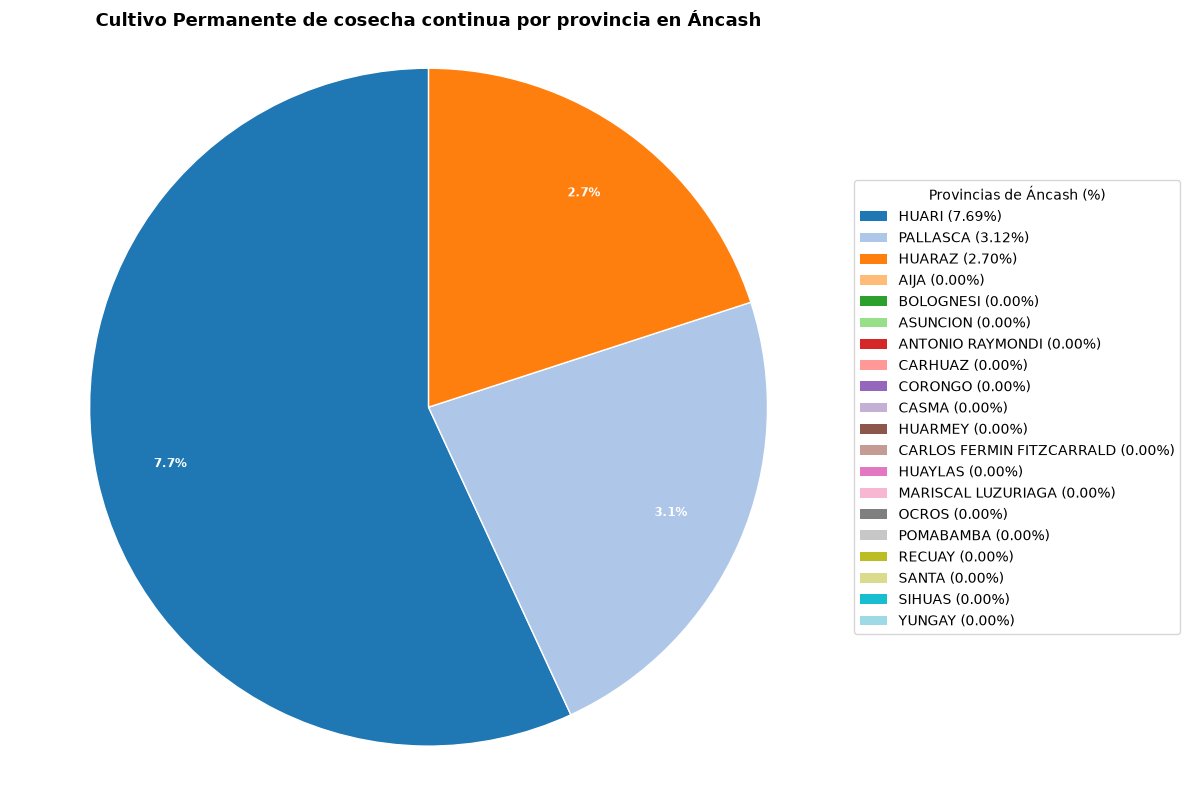

In [71]:
from matplotlib.patches import Patch

col_nombre = "Permanente de cosecha continua"
datos = resumen_tipo_cultivo_anc[col_nombre].sort_values(ascending=False)

color_100 = "#2e7d32"
paleta_otros = [c for c in plt.cm.tab20.colors if c != color_100]

colores_prov = []
idx_otro = 0
for val in datos.values:
    if round(val, 2) == 100:
        colores_prov.append(color_100)
    else:
        colores_prov.append(paleta_otros[idx_otro % len(paleta_otros)])
        idx_otro += 1

datos_pie = datos[datos > 0]
colores_pie = [c for val, c in zip(datos, colores_prov) if val > 0]

iter_valores = iter(datos_pie.values)
def mostrar_valor_real(_):
    val = next(iter_valores)
    return f"{val:.1f}%"

fig, ax = plt.subplots(figsize=(12, 8))

wedges, texts, autotexts = ax.pie(
    datos_pie,
    autopct=mostrar_valor_real,
    pctdistance=0.78,
    startangle=90,
    colors=colores_pie,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.setp(autotexts, size=8.5, weight="bold", color="white")

handles_leyenda = [
    Patch(facecolor=c, label=f"{prov} ({val:.2f}%)")
    for prov, val, c in zip(datos.index, datos.values, colores_prov)
]

ax.legend(
    handles=handles_leyenda,
    title="Provincias de Áncash (%)",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Cultivo {col_nombre} por provincia en Áncash", fontsize=13, fontweight="bold")
ax.axis("equal")
plt.tight_layout()
plt.show()

## 8-. Cultivos que sufrieron pérdida total de producción o superficie(P224B)

In [72]:
df_anc_p224b = df_ancash.dropna(subset=["P224B_NOM"])

tabla_p224b_anc = df_anc_p224b["P224B_NOM"].value_counts().reset_index()
tabla_p224b_anc.columns = ["cultivo_afectado", "cantidad_casos"]

total_casos = tabla_p224b_anc["cantidad_casos"].sum()
tabla_p224b_anc["porcentaje"] = (tabla_p224b_anc["cantidad_casos"] / total_casos) * 100

tabla_p224b_anc = tabla_p224b_anc.sort_values("cantidad_casos", ascending=False).reset_index(drop=True)

display(tabla_p224b_anc)

df_grafico_p224b = tabla_p224b_anc.set_index("cultivo_afectado")[["porcentaje"]]

,cultivo_afectado,cantidad_casos,porcentaje
0,PAPA BLANCA,55,26.315789
1,PALTO,30,14.354067
2,MAIZ AMILACEO,20,9.569378
3,ARVEJA,13,6.220096
4,TARHUI,11,5.263158
5,TRIGO,10,4.784689
6,HABA,8,3.827751
7,QUINUA,4,1.913876
8,OCA,4,1.913876
9,PAPA NATIVA,4,1.913876


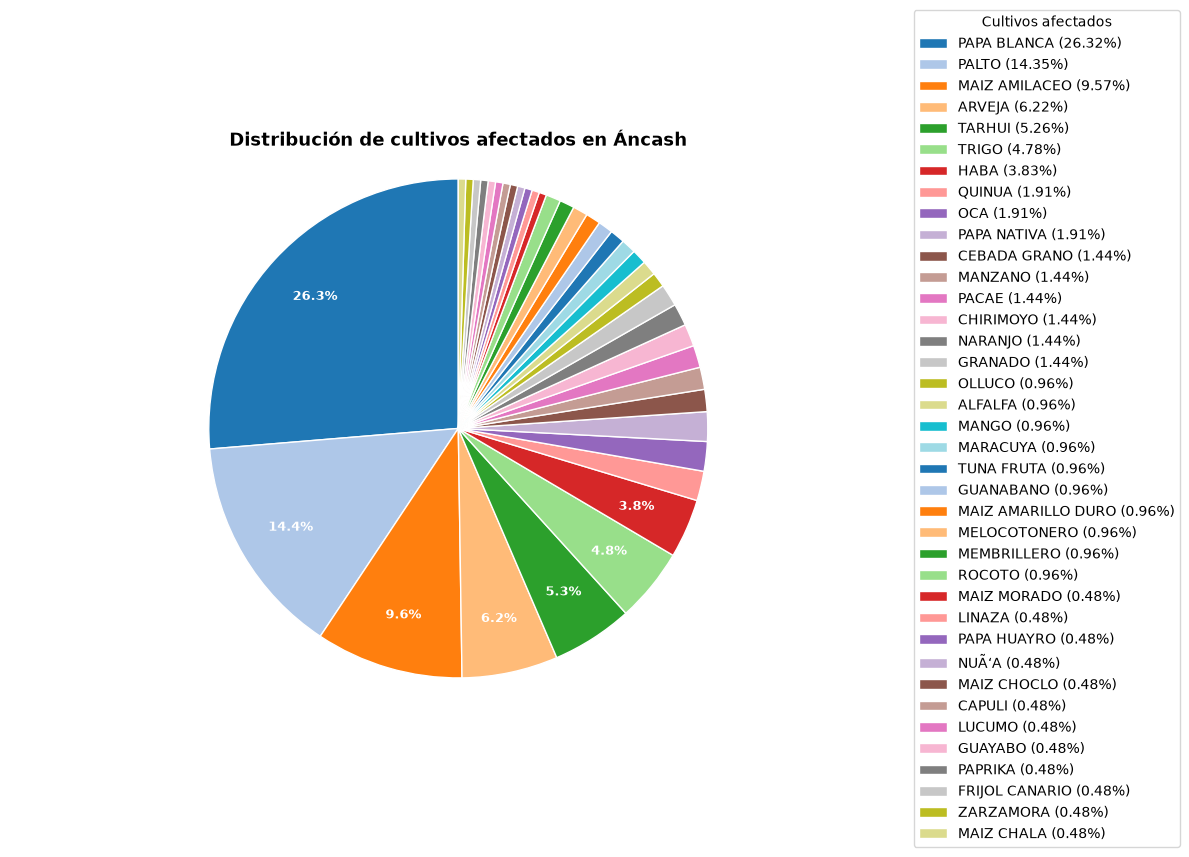

In [73]:
fig, ax = plt.subplots(figsize=(12, 8))

def mostrar_pct(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

wedges, texts, autotexts = ax.pie(
    tabla_p224b_anc["cantidad_casos"],
    autopct=mostrar_pct,
    startangle=90,
    pctdistance=0.78,
    colors=plt.cm.tab20.colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.setp(autotexts, size=9, weight="bold", color="white")

etiquetas = [
    f"{cultivo} ({pct:.2f}%)"
    for cultivo, pct in zip(tabla_p224b_anc["cultivo_afectado"], tabla_p224b_anc["porcentaje"])
]

ax.legend(
    wedges,
    etiquetas,
    title="Cultivos afectados",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Distribución de cultivos afectados en Áncash", fontsize=13, fontweight="bold")
ax.axis("equal")
plt.tight_layout()
plt.show()

## 9-.EN LOS ÚLTIMOS 12 MESES, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Agrícola? o ¿Pecuaria? (P142_1) (P142_2)

In [74]:
cols_p142 = ["P142_1", "P142_2"]

df_ancash[cols_p142] = df_ancash[cols_p142].apply(
    pd.to_numeric,
    errors="coerce"
)

sub_anc = df_ancash[cols_p142]

nombres_actividades = [
    "Actividad Agrícola",
    "Actividad Pecuaria"
]

tabla_p142_anc = pd.DataFrame({
    "actividad": nombres_actividades,
    "si_realizo": [sub_anc[c].eq(1).sum() for c in cols_p142],
    "no_realizo": [sub_anc[c].eq(0).sum() for c in cols_p142]
})

display(tabla_p142_anc)

,actividad,si_realizo,no_realizo
0,Actividad Agrícola,209,0
1,Actividad Pecuaria,186,23


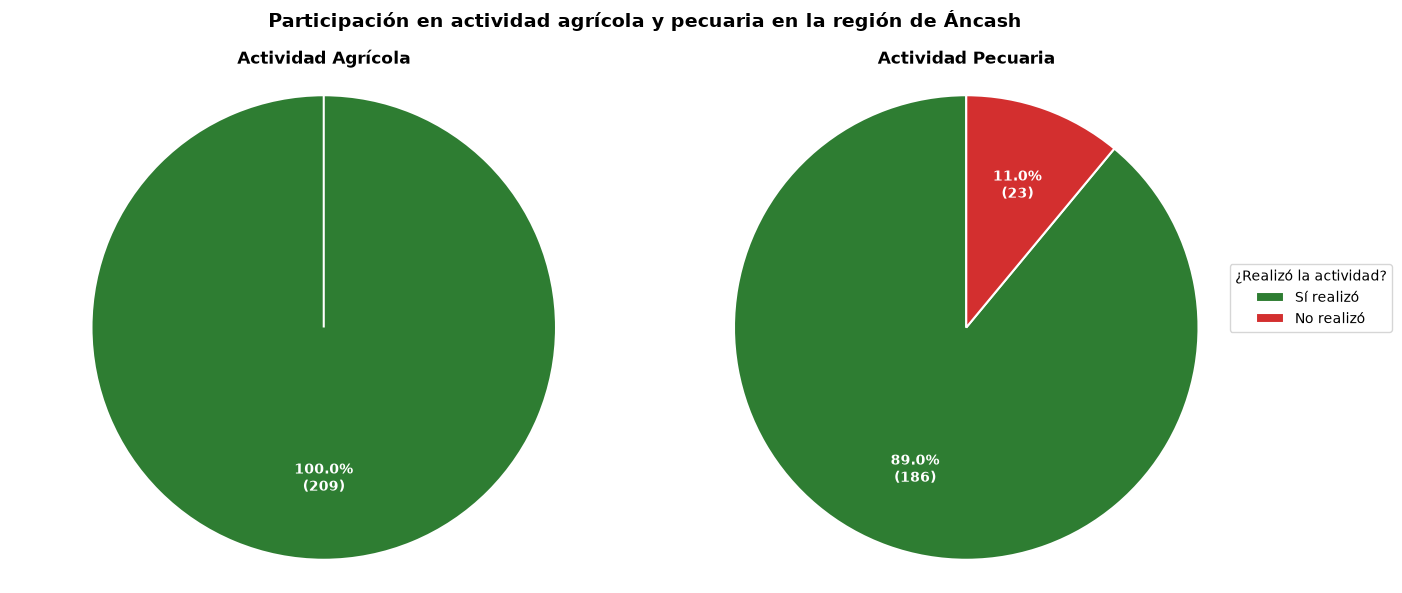

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

colores = ["#2e7d32", "#d32f2f"]  
etiquetas_leyenda = ["Sí realizó", "No realizó"]

for i, ax in enumerate(axes):
    fila = tabla_p142_anc.iloc[i]
    valores = [fila["si_realizo"], fila["no_realizo"]]
    total = sum(valores)
    
    def formato_etiqueta(pct):
        if pct == 0:
            return ""
        cantidad = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n({cantidad})"
    
    wedges, texts, autotexts = ax.pie(
        valores,
        autopct=formato_etiqueta,
        startangle=90,
        colors=colores,
        pctdistance=0.65,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}
    )
    
    plt.setp(autotexts, size=10, weight="bold", color="white")
    ax.set_title(fila["actividad"], fontsize=12, fontweight="bold")
    ax.axis("equal")

fig.legend(
    wedges,
    etiquetas_leyenda,
    title="¿Realizó la actividad?",
    loc="center right",
    bbox_to_anchor=(1.08, 0.5),
    fontsize=10
)

fig.suptitle(
    "Participación en actividad agrícola y pecuaria en la región de Áncash",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 10-. Superficie sembrada según cultivo (CULTIVO), (P224D_SUP_1)
### -comparar los valores de superficie sembrada de los diferentes cultivos.

In [90]:
if "CULTIVO" not in df_ancash.columns and "P224_NOM" in df_ancash.columns:
    df_ancash["CULTIVO"] = df_ancash["P224_NOM"]

df_ancash["SUPERFICIE"] = pd.to_numeric(
    df_ancash["P224D_SUP_1"],
    errors="coerce"
)

df_ancash["PROMEDIO_CULTIVO"] = df_ancash.groupby(
    "CULTIVO"
)["SUPERFICIE"].transform("mean")

tabla7 = df_ancash.groupby("CULTIVO").agg(
    Promedio=("PROMEDIO_CULTIVO", "mean"),
    Total=("SUPERFICIE", "sum"),
    Maximo=("SUPERFICIE", "max"),
    Minimo=("SUPERFICIE", "min")
).dropna().sort_values(
    by="Promedio",
    ascending=False
)

tabla7 = tabla7[tabla7["Promedio"] > 0]

display(tabla7)

,Promedio,Total,Maximo,Minimo
CULTIVO,,,,
TRIGO,620.000000,6200,5000,0
ARVEJA,476.923077,6200,5000,0
CEBADA GRANO,416.666667,1250,1250,0
MAIZ,348.160000,8704,7500,0
HABA,262.500000,2100,1500,0
PAPA BLANCA,227.272727,12500,4000,0
PAPA NATIVA,125.000000,500,500,0
PAPRIKA,1.000000,1,1,1
MARACUYA,1.000000,2,2,0


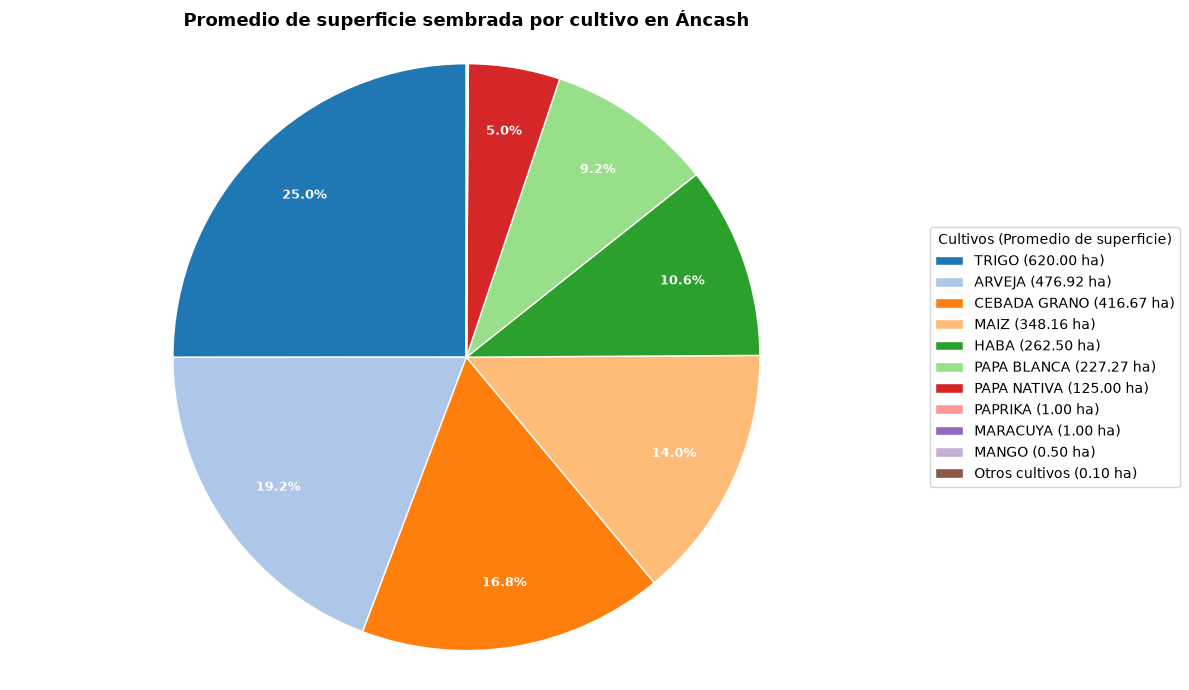

In [91]:
if len(tabla7) > 10:
    top10 = tabla7.head(10)[["Promedio"]].copy()
    otros_val = tabla7.iloc[10:]["Promedio"].sum()
    top10.loc["Otros cultivos"] = otros_val
    datos_graf = top10["Promedio"]
else:
    datos_graf = tabla7["Promedio"]

fig, ax = plt.subplots(figsize=(12, 7))

def mostrar_pct(pct):
    return f"{pct:.1f}%" if pct >= 4 else ""

wedges, texts, autotexts = ax.pie(
    datos_graf,
    autopct=mostrar_pct,
    startangle=90,
    pctdistance=0.78,
    colors=plt.cm.tab20.colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.setp(autotexts, size=9, weight="bold", color="white")

etiquetas = [
    f"{cultivo} ({prom:.2f} ha)"
    for cultivo, prom in zip(datos_graf.index, datos_graf.values)
]

ax.legend(
    wedges,
    etiquetas,
    title="Cultivos (Promedio de superficie)",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title("Promedio de superficie sembrada por cultivo en Áncash", fontsize=13, fontweight="bold")
ax.axis("equal")
plt.tight_layout()
plt.show()